# Data Preparation

In [7]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [8]:
# File paths (adjust as needed if running locally)
file_path_stocks = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\Data\BYD&Tesla.xlsx'
file_path_indices = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\Data\恒生&纳斯达克.xlsx'

# Read stock prices (BYD and Tesla)
stocks = pd.read_excel(
    file_path_stocks,
    header=0,
    skiprows=[0],
    index_col='日期',
    parse_dates=['日期'],
    date_parser=lambda x: pd.to_datetime(x, format='%Y-%m-%d')
)
stocks = stocks[['比亚迪股份', '特斯拉(TESLA)']]
stocks.columns = ['BYD', 'TESLA']
stocks = stocks[(stocks['BYD'] > 0) & (stocks['TESLA'] > 0)]

# Read index prices (HSI and IXIC)
indices = pd.read_excel(
    file_path_indices,
    header=0,
    skiprows=[0],
    index_col='日期',
    parse_dates=['日期'],
    date_parser=lambda x: pd.to_datetime(x, format='%Y-%m-%d')
)
indices = indices[['恒生指数', '纳斯达克指数']]
indices.columns = ['HSI', 'IXIC']
indices = indices[(indices['HSI'] > 0) & (indices['IXIC'] > 0)]

# Align dates by taking the intersection
common_dates = stocks.index.intersection(indices.index)
stocks = stocks.loc[common_dates]
indices = indices.loc[common_dates]

# Compute log prices
log_stocks = np.log(stocks)
log_indices = np.log(indices)

# Compute daily log returns and drop NaN values
returns = pd.DataFrame({
    'BYD': log_stocks['BYD'].diff(),
    'TESLA': log_stocks['TESLA'].diff(),
    'HSI': log_indices['HSI'].diff(),
    'IXIC': log_indices['IXIC'].diff()
}).dropna()

# 1. CAPM Analysis

CAPM models the expected return of an asset as:
$$R_{\text{asset}} = \alpha + \beta \cdot R_{\text{market}} + \epsilon$$
where:
- $R_{\text{asset}}$: Asset return (e.g., BYD or Tesla).
- $R_{\text{market}}$: Market return (e.g., HSI or IXIC).
- $\beta$: Sensitivity of the asset to the market.
- $\alpha$: Intercept (not typically interpreted in basic CAPM without a risk-free rate).
- $\epsilon$: Error term.

In [9]:
def generate_model_table(model, model_name, dep_var_display, indep_var_display):
    """Generate styled table for model results."""
    variables = model.model.exog_names
    indep_var_actual = variables[1]  # First variable after constant
    
    # Extract metrics
    alpha = model.params['const']
    alpha_p = model.pvalues['const']
    beta = model.params[indep_var_actual]
    beta_p = model.pvalues[indep_var_actual]
    r_squared = model.rsquared
    obs = model.nobs
    
    # Create figure
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.axis('off')
    
    # Configure table content
    cell_text = []
    cell_colors = []
    
    # Model Information
    cell_text.append(['Model Information', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    cell_text.append(['  Dependent Variable', dep_var_display])
    cell_colors.append(['#ffffff', '#ffffff'])
    cell_text.append(['  Independent Variable', indep_var_display])
    cell_colors.append(['#ffffff', '#ffffff'])
    cell_text.append(['  Number of Observations', f"{obs:,}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Coefficients
    cell_text.append(['Coefficients', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    
    # Alpha
    cell_text.append(['  Intercept (α)', f"{alpha:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    alpha_p_str = f"{alpha_p:.4f}" if alpha_p >= 0.0001 else f"{alpha_p:.2e}"
    cell_text.append(['  p-value', alpha_p_str])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Beta
    cell_text.append(['  Beta (β)', f"{beta:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    beta_p_str = f"{beta_p:.4f}" if beta_p >= 0.0001 else f"{beta_p:.2e}"
    cell_text.append(['  p-value', beta_p_str])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Model Fit
    cell_text.append(['Model Fit', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    cell_text.append(['  R-squared', f"{r_squared:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Create table
    table = ax.table(
        cellText=cell_text, 
        cellColours=cell_colors,
        colLabels=['Metric', 'Value'],
        loc='center',
        cellLoc='left'
    )
    
    # Formatting
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1.2, 1.5)

    # Style headers
    for (row, col), cell in table.get_celld().items():
        # Handle header and first column styling
        if row == 0 or col == -1:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#40466e')
        
        # Only process data rows (skip header row)
        if row > 0:
            # Adjust for header offset in cell_text
            adjusted_row = row - 1
            # Ensure we don't exceed cell_text bounds
            if adjusted_row < len(cell_text):
                metric_name = cell_text[adjusted_row][0].strip()
                # Apply bold to section headers
                if metric_name in ['Model Information', 'Coefficients', 'Model Fit']:
                    cell.set_text_props(weight='bold')

    plt.title(model_name, fontsize=15, pad=20)
    plt.tight_layout()
    return fig

### 1.1 BYD vs. HSI

<Figure size 640x480 with 0 Axes>

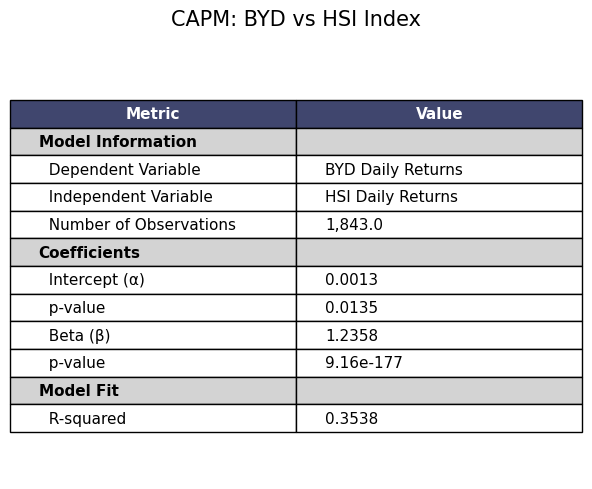

In [10]:
# Run regression
X = sm.add_constant(returns['HSI'])
model_byd = sm.OLS(returns['BYD'], X).fit()

# Generate table
plt.figure()
fig_byd = generate_model_table(
    model_byd,
    "CAPM: BYD vs HSI Index",
    "BYD Daily Returns",
    "HSI Daily Returns"
)
plt.show()

### 1.2 Tesla vs. NASDAQ

<Figure size 640x480 with 0 Axes>

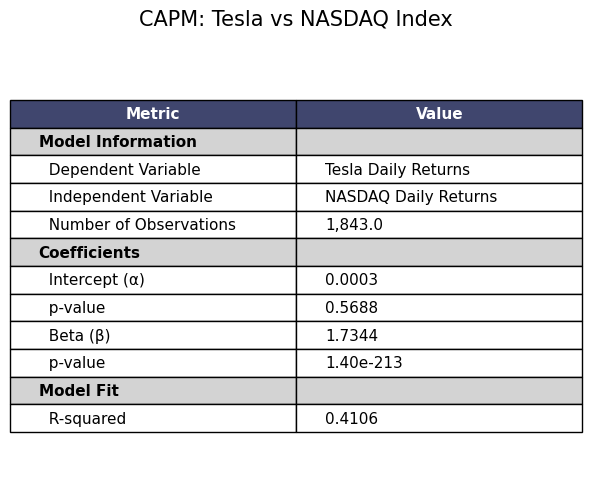

In [11]:
# Run regression
X = sm.add_constant(returns['IXIC'])
model_tesla = sm.OLS(returns['TESLA'], X).fit()

# Generate table
plt.figure()
fig_tesla = generate_model_table(
    model_tesla,
    "CAPM: Tesla vs NASDAQ Index",
    "Tesla Daily Returns",
    "NASDAQ Daily Returns"
)
plt.show()

# 2. Market Spread Analysis

<Figure size 640x480 with 0 Axes>

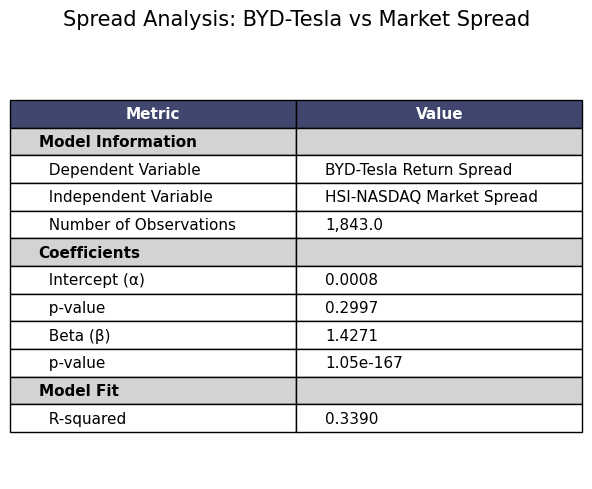

In [12]:
# Calculate spreads
spread_return = returns['BYD'] - returns['TESLA']
market_spread_return = (returns['HSI'] - returns['IXIC']).rename('market_spread')

# Run regression
X = sm.add_constant(market_spread_return)
model_spread = sm.OLS(spread_return, X).fit()

# Generate table
plt.figure()
fig_spread = generate_model_table(
    model_spread,
    "Spread Analysis: BYD-Tesla vs Market Spread",
    "BYD-Tesla Return Spread",
    "HSI-NASDAQ Market Spread"
)
plt.show()